# 경로 설정

In [4]:
BASE_DIR = "lerobot_project"
VENV_NAME = "lerobot_env"
PYTHON_VERSION = "3.12"
REPO_NAME = "lerobot-ac-mlp"

import os, sys, subprocess
os.environ['MPLBACKEND'] = 'Agg'
home_dir = os.path.expanduser('~')
base_path = os.path.join(home_dir, BASE_DIR)
venv_path = os.path.join(base_path, VENV_NAME)
site_packages = os.path.join(venv_path, 'lib', f'python{PYTHON_VERSION}', 'site-packages')
if site_packages not in sys.path: sys.path.insert(0, site_packages)
python_exec = os.path.join(venv_path, 'bin', 'python')
pip_exec = os.path.join(venv_path, 'bin', 'pip')
project_dir = os.path.join(base_path, REPO_NAME)
src_path = os.path.join(project_dir, 'src')
if src_path not in sys.path: sys.path.insert(0, src_path)

# --- 렌더링 환경 설정 (osmesa) ---
conda_lib = os.path.join(home_dir, 'miniconda3', 'lib')
lib_dirs = {conda_lib}
r = subprocess.run(['bash', '-c', f'find {home_dir}/miniconda3 -name "libOSMesa*" -o -name "libEGL*" 2>/dev/null'],
                    capture_output=True, text=True, timeout=15)
for line in r.stdout.strip().split('\n'):
    if line.strip(): lib_dirs.add(os.path.dirname(line.strip()))
ld_path = ':'.join(lib_dirs) + ':' + os.environ.get('LD_LIBRARY_PATH', '')
os.environ['LD_LIBRARY_PATH'] = ld_path
os.environ['MUJOCO_GL'] = 'osmesa'

%cd {project_dir}
print(f"Project: {project_dir}")
print(f"Rendering: {os.environ['MUJOCO_GL']}")
!git branch --show-current

/home1/eunji24/lerobot_project/lerobot-ac-mlp
Project: /home1/eunji24/lerobot_project/lerobot-ac-mlp
Rendering: osmesa
/bin/bash: /home1/eunji24/miniconda3/lib/libtinfo.so.6: no version information available (required by /bin/bash)
ecd-eunji


In [5]:
import os
from pathlib import Path

print("cwd:", os.getcwd())

for p in Path(".").glob("**/episode_*.pt"):
    print(p)

cwd: /home1/eunji24/lerobot_project/lerobot-ac-mlp
outputs/eval/act_ens_0005/videos/action_logs/episode_0005.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0034.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0015.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0022.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0036.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0048.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0010.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0027.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0028.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0042.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0031.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0024.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0037.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0001.pt
outputs/eval/act_ens_0005/videos/action_logs/episode_0030.pt
outputs/eval/act_ens_0005/videos/a

# baseline과 temporal ensemble
boundary jump & jerk

=== baseline vs ensemble ===
baseline mean jerk: 0.05385011062026024
ensemble mean jerk: 0.0014324468793347478
baseline mean boundary jump: 0.12427615374326706
ensemble mean boundary jump: 0.018831245601177216


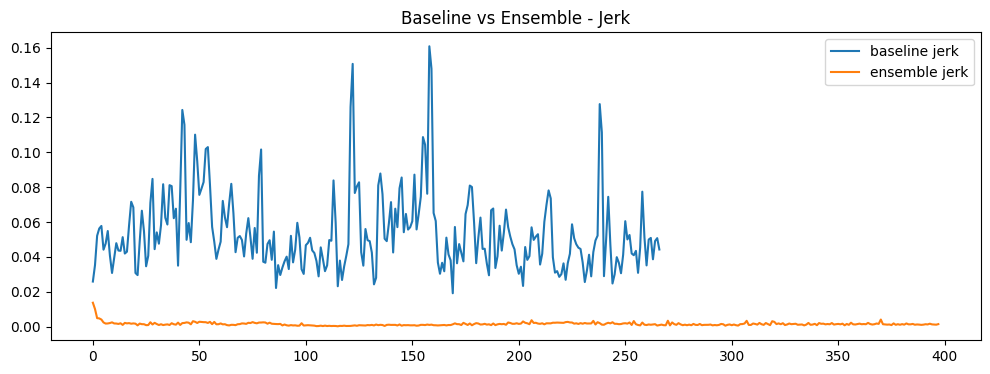

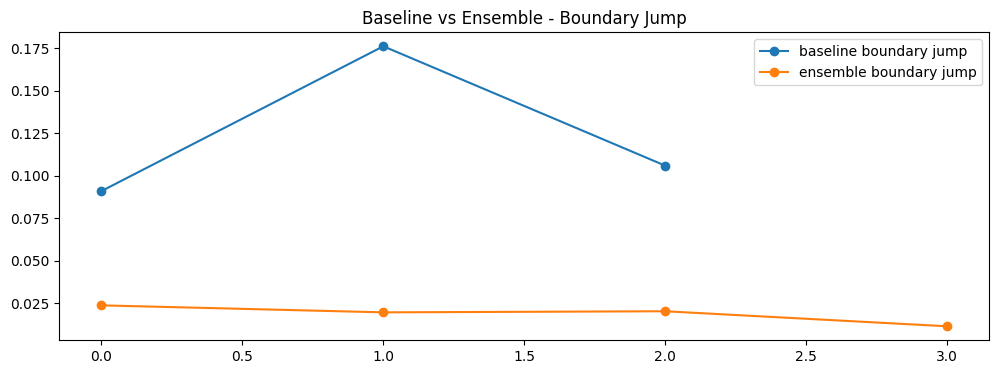

In [6]:
%matplotlib inline
import torch
import matplotlib.pyplot as plt

BASE_PATH = "outputs/eval/acm_ens_test_100k_50/ens_base_actionlog/videos/action_logs/episode_0001.pt"
ORIG_PATH = "outputs/eval/acm_temporal_001/videos/action_logs/episode_0001.pt"

N_ACTION_STEPS = 80

def load_actions(path):
    data = torch.load(path)
    actions = data["actions"].float()
    if actions.ndim == 3 and actions.shape[1] == 1:
        actions = actions.squeeze(1)
    return actions

def jerk_l2(actions):
    jerk = actions[2:] - 2 * actions[1:-1] + actions[:-2]
    return torch.norm(jerk, dim=-1)

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if vals else None

base = load_actions(BASE_PATH)
orig = load_actions(ORIG_PATH)

base_jerk = jerk_l2(base)
orig_jerk = jerk_l2(orig)

base_jump = boundary_jump(base, N_ACTION_STEPS)
orig_jump = boundary_jump(orig, N_ACTION_STEPS)

print("=== baseline vs ensemble ===")
print("baseline mean jerk:", base_jerk.mean().item())
print("ensemble mean jerk:", orig_jerk.mean().item())

print("baseline mean boundary jump:", base_jump.mean().item() if base_jump is not None else None)
print("ensemble mean boundary jump:", orig_jump.mean().item() if orig_jump is not None else None)

plt.figure(figsize=(12,4))
plt.plot(base_jerk.numpy(), label="baseline jerk")
plt.plot(orig_jerk.numpy(), label="ensemble jerk")
plt.title("Baseline vs Ensemble - Jerk")
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
if base_jump is not None:
    plt.plot(base_jump.numpy(), marker="o", label="baseline boundary jump")
if orig_jump is not None:
    plt.plot(orig_jump.numpy(), marker="o", label="ensemble boundary jump")
plt.title("Baseline vs Ensemble - Boundary Jump")
plt.legend()
plt.show()

# baseline과 chunk ensemble
boundary jump & jerk

In [ ]:
%matplotlib inline
import torch
import matplotlib.pyplot as plt

BASE_PATH = "outputs/eval/acm_ens_test_100k_50/ens_base_actionlog/videos/action_logs/episode_0001.pt"
ORIG_PATH = "outputs/eval/acm_ens_test_100k_50/ens_coeff_001_actionlog/videos/action_logs/episode_0001.pt"

N_ACTION_STEPS = 80

def load_actions(path):
    data = torch.load(path)
    actions = data["actions"].float()
    if actions.ndim == 3 and actions.shape[1] == 1:
        actions = actions.squeeze(1)
    return actions

def jerk_l2(actions):
    jerk = actions[2:] - 2 * actions[1:-1] + actions[:-2]
    return torch.norm(jerk, dim=-1)

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if vals else None

base = load_actions(BASE_PATH)
orig = load_actions(ORIG_PATH)

base_jerk = jerk_l2(base)
orig_jerk = jerk_l2(orig)

base_jump = boundary_jump(base, N_ACTION_STEPS)
orig_jump = boundary_jump(orig, N_ACTION_STEPS)

print("=== baseline vs ensemble ===")
print("baseline mean jerk:", base_jerk.mean().item())
print("ensemble mean jerk:", orig_jerk.mean().item())

print("baseline mean boundary jump:", base_jump.mean().item() if base_jump is not None else None)
print("ensemble mean boundary jump:", orig_jump.mean().item() if orig_jump is not None else None)

plt.figure(figsize=(12,4))
plt.plot(base_jerk.numpy(), label="baseline jerk")
plt.plot(orig_jerk.numpy(), label="ensemble jerk")
plt.title("Baseline vs Ensemble - Jerk")
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
if base_jump is not None:
    plt.plot(base_jump.numpy(), marker="o", label="baseline boundary jump")
if orig_jump is not None:
    plt.plot(orig_jump.numpy(), marker="o", label="ensemble boundary jump")
plt.title("Baseline vs Ensemble - Boundary Jump")
plt.legend()
plt.show()

step 40

=== baseline vs ensemble ===
baseline mean jerk: 0.05385011062026024
ensemble mean jerk: 0.039818134158849716
baseline mean boundary jump: 0.12427615374326706
ensemble mean boundary jump: 0.06234704703092575


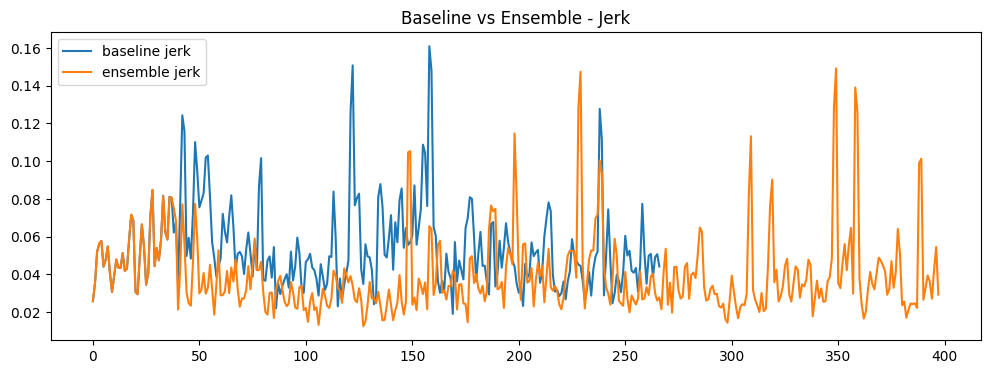

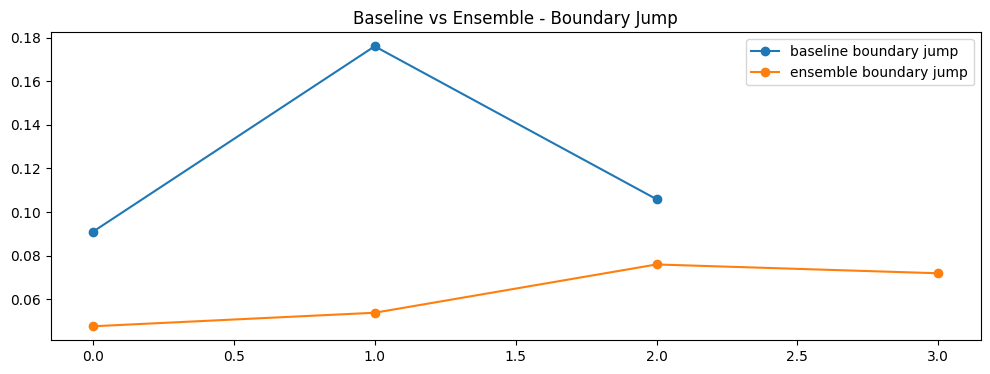

In [12]:
%matplotlib inline
import torch
import matplotlib.pyplot as plt

BASE_PATH = "outputs/eval/acm_ens_test_100k_50/ens_base_actionlog/videos/action_logs/episode_0001.pt"
ORIG_PATH = "outputs/eval/acm_ens_test_100k_50/ens_step_40_001/videos/action_logs/episode_0001.pt"

N_ACTION_STEPS = 80

def load_actions(path):
    data = torch.load(path)
    actions = data["actions"].float()
    if actions.ndim == 3 and actions.shape[1] == 1:
        actions = actions.squeeze(1)
    return actions

def jerk_l2(actions):
    jerk = actions[2:] - 2 * actions[1:-1] + actions[:-2]
    return torch.norm(jerk, dim=-1)

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if vals else None

base = load_actions(BASE_PATH)
orig = load_actions(ORIG_PATH)

base_jerk = jerk_l2(base)
orig_jerk = jerk_l2(orig)

base_jump = boundary_jump(base, N_ACTION_STEPS)
orig_jump = boundary_jump(orig, N_ACTION_STEPS)

print("=== baseline vs ensemble ===")
print("baseline mean jerk:", base_jerk.mean().item())
print("ensemble mean jerk:", orig_jerk.mean().item())

print("baseline mean boundary jump:", base_jump.mean().item() if base_jump is not None else None)
print("ensemble mean boundary jump:", orig_jump.mean().item() if orig_jump is not None else None)

plt.figure(figsize=(12,4))
plt.plot(base_jerk.numpy(), label="baseline jerk")
plt.plot(orig_jerk.numpy(), label="ensemble jerk")
plt.title("Baseline vs Ensemble - Jerk")
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
if base_jump is not None:
    plt.plot(base_jump.numpy(), marker="o", label="baseline boundary jump")
if orig_jump is not None:
    plt.plot(orig_jump.numpy(), marker="o", label="ensemble boundary jump")
plt.title("Baseline vs Ensemble - Boundary Jump")
plt.legend()
plt.show()

In [ ]:
%matplotlib inline
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

EPISODE = 1
N_ACTION_STEPS = 80   # baseline 기준 boundary 간격

PATHS = {
    "baseline": "outputs/eval/acm_ens_test_100k_50/ens_base_actionlog/videos/action_logs",
    "step_1":   "outputs/eval/acm_ens_test_100k_50/orign_ens_coeff_001_actionlog/videos/action_logs",
    "step_20":  "outputs/eval/acm_ens_test_100k_50/ens_step_20_001/videos/action_logs",
    "step_40":  "outputs/eval/acm_ens_test_100k_50/ens_step_40_001/videos/action_logs",
    "step_60":  "outputs/eval/acm_ens_test_100k_50/ens_step_60_001/videos/action_logs",
    "step_80":  "outputs/eval/acm_ens_test_100k_50/ens_coeff_001_actionlog/videos/action_logs",
}

def load_actions(log_dir, episode):
    path = os.path.join(log_dir, f"episode_{episode:04d}.pt")
    data = torch.load(path)
    actions = data["actions"].float()
    if actions.ndim == 3 and actions.shape[1] == 1:
        actions = actions.squeeze(1)
    return actions

def jerk_l2(actions):
    if actions.shape[0] < 3:
        return None
    jerk = actions[2:] - 2 * actions[1:-1] + actions[:-2]
    return torch.norm(jerk, dim=-1)

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if vals else None

results = {}

for name, log_dir in PATHS.items():
    actions = load_actions(log_dir, EPISODE)
    jerk = jerk_l2(actions)
    jump = boundary_jump(actions, N_ACTION_STEPS)

    results[name] = {
        "actions": actions,
        "jerk": jerk,
        "jump": jump,
        "mean_jerk": jerk.mean().item() if jerk is not None else None,
        "mean_jump": jump.mean().item() if jump is not None else None,
    }
print(f"=== episode_{EPISODE:04d} 비교 ===")
for name, r in results.items():
    mj = "None" if r["mean_jerk"] is None else f"{r['mean_jerk']:.6f}"
    mb = "None" if r["mean_jump"] is None else f"{r['mean_jump']:.6f}"
    print(f"{name:>8} | mean jerk: {mj} | mean boundary jump: {mb}")

# action plot 비교지표
base vs 0.01

ens_150_80/base vs ens_150_80/0.01

In [ ]:
import torch
import matplotlib.pyplot as plt

base = torch.load("outputs/debug_action_logs/episode_0002.pt")
ens = torch.load("outputs/debug_action_logs/ens/episode_0002.pt")

base_actions = base["actions"]
ens_actions = ens["actions"]

if base_actions.ndim == 3:
    base_actions = base_actions.squeeze(1)
if ens_actions.ndim == 3:
    ens_actions = ens_actions.squeeze(1)

print("base shape:", base_actions.shape)
print("ens shape:", ens_actions.shape)

# 1) baseline vs ensemble 차이
T = min(base_actions.shape[0], ens_actions.shape[0])
base_actions = base_actions[:T]
ens_actions = ens_actions[:T]

diff = ens_actions - base_actions
diff_l2 = torch.norm(diff, dim=-1)

print("mean action diff L2:", diff_l2.mean().item())
print("max action diff L2:", diff_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(diff_l2.numpy())
plt.title("Baseline vs Ensemble action difference (L2)")
plt.xlabel("Step")
plt.ylabel("L2 diff")
plt.show()

# 2) jerk
base_jerk = base_actions[2:] - 2 * base_actions[1:-1] + base_actions[:-2]
ens_jerk = ens_actions[2:] - 2 * ens_actions[1:-1] + ens_actions[:-2]

base_jerk_l2 = torch.norm(base_jerk, dim=-1)
ens_jerk_l2 = torch.norm(ens_jerk, dim=-1)

print("baseline mean jerk:", base_jerk_l2.mean().item())
print("ensemble mean jerk:", ens_jerk_l2.mean().item())
print("baseline max jerk:", base_jerk_l2.max().item())
print("ensemble max jerk:", ens_jerk_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(base_jerk_l2.numpy(), label="baseline jerk")
plt.plot(ens_jerk_l2.numpy(), label="ensemble jerk")
plt.legend()
plt.title("Jerk L2 over time")
plt.xlabel("Step")
plt.ylabel("Jerk L2")
plt.show()

# 3) boundary jump / boundary jerk
n_action_steps = 80

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

def boundary_jerk(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        if b >= 2:
            vals.append(torch.norm(actions[b] - 2 * actions[b - 1] + actions[b - 2], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

base_jump = boundary_jump(base_actions, n_action_steps)
ens_jump = boundary_jump(ens_actions, n_action_steps)

base_bjerk = boundary_jerk(base_actions, n_action_steps)
ens_bjerk = boundary_jerk(ens_actions, n_action_steps)

if base_jump is not None and ens_jump is not None:
    print("baseline boundary jump mean:", base_jump.mean().item())
    print("ensemble boundary jump mean:", ens_jump.mean().item())
    print("baseline boundary jump max:", base_jump.max().item())
    print("ensemble boundary jump max:", ens_jump.max().item())

if base_bjerk is not None and ens_bjerk is not None:
    print("baseline boundary jerk mean:", base_bjerk.mean().item())
    print("ensemble boundary jerk mean:", ens_bjerk.mean().item())
    print("baseline boundary jerk max:", base_bjerk.max().item())
    print("ensemble boundary jerk max:", ens_bjerk.max().item())

# action plot 비교
base vs 0.1

ens_150_80_base vs ens_150_0.1

base shape: torch.Size([275, 14])
ens shape: torch.Size([279, 14])
mean action diff L2: 0.43181636929512024
max action diff L2: 1.2678085565567017


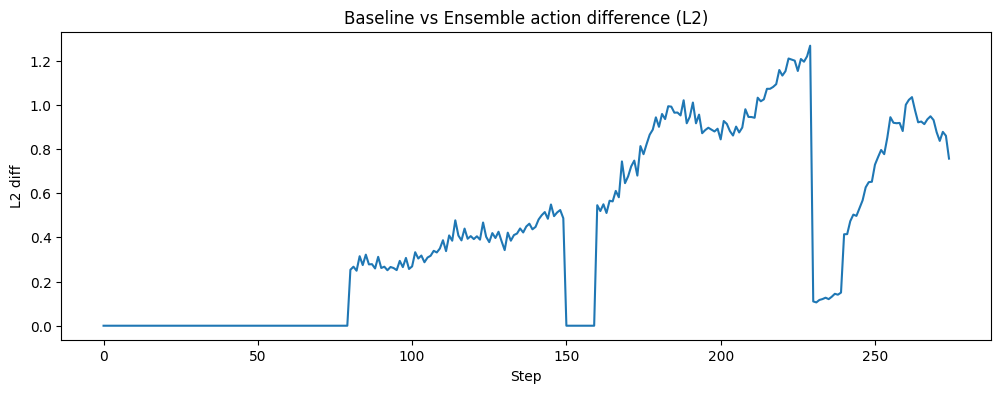

baseline mean jerk: 0.2662660777568817
ensemble mean jerk: 0.2249011993408203
baseline max jerk: 1.0450505018234253
ensemble max jerk: 1.3280786275863647


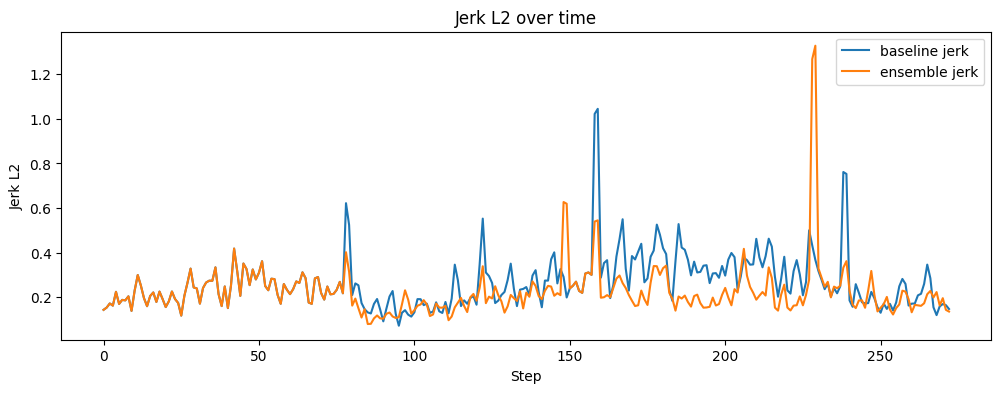

baseline boundary jump mean: 0.7775440216064453
ensemble boundary jump mean: 0.400073379278183
baseline boundary jump max: 1.0387206077575684
ensemble boundary jump max: 0.5553429126739502
baseline boundary jerk mean: 0.8018935322761536
ensemble boundary jerk mean: 0.4246545732021332
baseline boundary jerk max: 1.0221712589263916
ensemble boundary jerk max: 0.5393792986869812


In [8]:
import torch
import matplotlib.pyplot as plt

base = torch.load("outputs/debug_action_logs/base/episode_0002.pt")
ens = torch.load("outputs/debug_action_logs/0.1/episode_0002.pt")

base_actions = base["actions"]
ens_actions = ens["actions"]

if base_actions.ndim == 3:
    base_actions = base_actions.squeeze(1)
if ens_actions.ndim == 3:
    ens_actions = ens_actions.squeeze(1)

print("base shape:", base_actions.shape)
print("ens shape:", ens_actions.shape)

# 1) baseline vs ensemble 차이
T = min(base_actions.shape[0], ens_actions.shape[0])
base_actions = base_actions[:T]
ens_actions = ens_actions[:T]

diff = ens_actions - base_actions
diff_l2 = torch.norm(diff, dim=-1)

print("mean action diff L2:", diff_l2.mean().item())
print("max action diff L2:", diff_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(diff_l2.numpy())
plt.title("Baseline vs Ensemble action difference (L2)")
plt.xlabel("Step")
plt.ylabel("L2 diff")
plt.show()

# 2) jerk
base_jerk = base_actions[2:] - 2 * base_actions[1:-1] + base_actions[:-2]
ens_jerk = ens_actions[2:] - 2 * ens_actions[1:-1] + ens_actions[:-2]

base_jerk_l2 = torch.norm(base_jerk, dim=-1)
ens_jerk_l2 = torch.norm(ens_jerk, dim=-1)

print("baseline mean jerk:", base_jerk_l2.mean().item())
print("ensemble mean jerk:", ens_jerk_l2.mean().item())
print("baseline max jerk:", base_jerk_l2.max().item())
print("ensemble max jerk:", ens_jerk_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(base_jerk_l2.numpy(), label="baseline jerk")
plt.plot(ens_jerk_l2.numpy(), label="ensemble jerk")
plt.legend()
plt.title("Jerk L2 over time")
plt.xlabel("Step")
plt.ylabel("Jerk L2")
plt.show()

# 3) boundary jump / boundary jerk
n_action_steps = 80

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

def boundary_jerk(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        if b >= 2:
            vals.append(torch.norm(actions[b] - 2 * actions[b - 1] + actions[b - 2], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

base_jump = boundary_jump(base_actions, n_action_steps)
ens_jump = boundary_jump(ens_actions, n_action_steps)

base_bjerk = boundary_jerk(base_actions, n_action_steps)
ens_bjerk = boundary_jerk(ens_actions, n_action_steps)

if base_jump is not None and ens_jump is not None:
    print("baseline boundary jump mean:", base_jump.mean().item())
    print("ensemble boundary jump mean:", ens_jump.mean().item())
    print("baseline boundary jump max:", base_jump.max().item())
    print("ensemble boundary jump max:", ens_jump.max().item())

if base_bjerk is not None and ens_bjerk is not None:
    print("baseline boundary jerk mean:", base_bjerk.mean().item())
    print("ensemble boundary jerk mean:", ens_bjerk.mean().item())
    print("baseline boundary jerk max:", base_bjerk.max().item())
    print("ensemble boundary jerk max:", ens_bjerk.max().item())

base shape: torch.Size([275, 14])
ens shape: torch.Size([400, 14])
mean action diff L2: 1.8224592208862305
max action diff L2: 4.972412109375


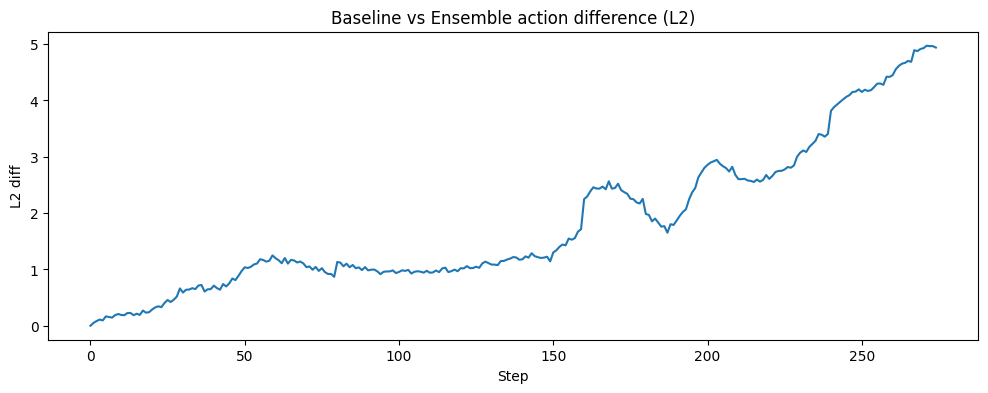

baseline mean jerk: 0.2662660777568817
ensemble mean jerk: 0.01564023084938526
baseline max jerk: 1.0450505018234253
ensemble max jerk: 0.07918769866228104


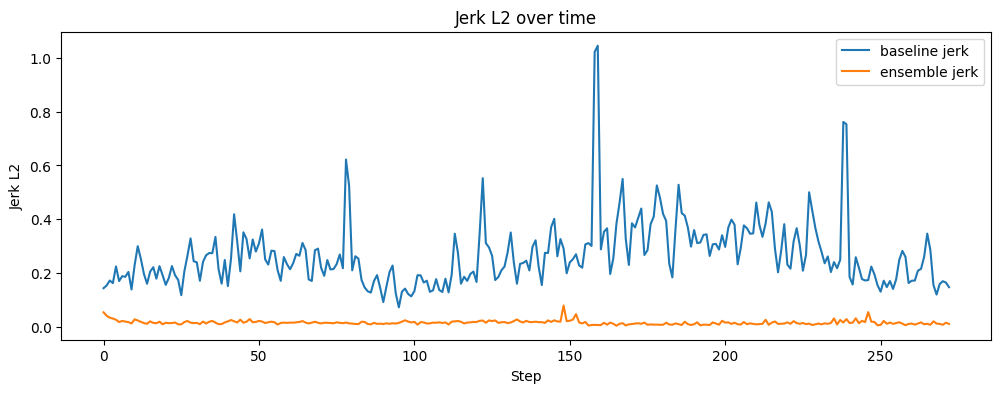

baseline boundary jump mean: 0.7775440216064453
ensemble boundary jump mean: 0.05921320244669914
baseline boundary jump max: 1.0387206077575684
ensemble boundary jump max: 0.06219247356057167
baseline boundary jerk mean: 0.8018935322761536
ensemble boundary jerk mean: 0.01290751714259386
baseline boundary jerk max: 1.0221712589263916
ensemble boundary jerk max: 0.015924474224448204


In [14]:
import torch
import matplotlib.pyplot as plt

base = torch.load("outputs/debug_action_logs/base/episode_0002.pt")
ens = torch.load("outputs/debug_action_logs/step/episode_0002.pt")

base_actions = base["actions"]
ens_actions = ens["actions"]

if base_actions.ndim == 3:
    base_actions = base_actions.squeeze(1)
if ens_actions.ndim == 3:
    ens_actions = ens_actions.squeeze(1)

print("base shape:", base_actions.shape)
print("ens shape:", ens_actions.shape)

# 1) baseline vs ensemble 차이
T = min(base_actions.shape[0], ens_actions.shape[0])
base_actions = base_actions[:T]
ens_actions = ens_actions[:T]

diff = ens_actions - base_actions
diff_l2 = torch.norm(diff, dim=-1)

print("mean action diff L2:", diff_l2.mean().item())
print("max action diff L2:", diff_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(diff_l2.numpy())
plt.title("Baseline vs Ensemble action difference (L2)")
plt.xlabel("Step")
plt.ylabel("L2 diff")
plt.show()

# 2) jerk
base_jerk = base_actions[2:] - 2 * base_actions[1:-1] + base_actions[:-2]
ens_jerk = ens_actions[2:] - 2 * ens_actions[1:-1] + ens_actions[:-2]

base_jerk_l2 = torch.norm(base_jerk, dim=-1)
ens_jerk_l2 = torch.norm(ens_jerk, dim=-1)

print("baseline mean jerk:", base_jerk_l2.mean().item())
print("ensemble mean jerk:", ens_jerk_l2.mean().item())
print("baseline max jerk:", base_jerk_l2.max().item())
print("ensemble max jerk:", ens_jerk_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(base_jerk_l2.numpy(), label="baseline jerk")
plt.plot(ens_jerk_l2.numpy(), label="ensemble jerk")
plt.legend()
plt.title("Jerk L2 over time")
plt.xlabel("Step")
plt.ylabel("Jerk L2")
plt.show()

# 3) boundary jump / boundary jerk
n_action_steps = 80

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

def boundary_jerk(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        if b >= 2:
            vals.append(torch.norm(actions[b] - 2 * actions[b - 1] + actions[b - 2], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

base_jump = boundary_jump(base_actions, n_action_steps)
ens_jump = boundary_jump(ens_actions, n_action_steps)

base_bjerk = boundary_jerk(base_actions, n_action_steps)
ens_bjerk = boundary_jerk(ens_actions, n_action_steps)

if base_jump is not None and ens_jump is not None:
    print("baseline boundary jump mean:", base_jump.mean().item())
    print("ensemble boundary jump mean:", ens_jump.mean().item())
    print("baseline boundary jump max:", base_jump.max().item())
    print("ensemble boundary jump max:", ens_jump.max().item())

if base_bjerk is not None and ens_bjerk is not None:
    print("baseline boundary jerk mean:", base_bjerk.mean().item())
    print("ensemble boundary jerk mean:", ens_bjerk.mean().item())
    print("baseline boundary jerk max:", base_bjerk.max().item())
    print("ensemble boundary jerk max:", ens_bjerk.max().item())

base shape: torch.Size([400, 14])
ens shape: torch.Size([279, 14])
mean action diff L2: 0.15243671834468842
max action diff L2: 2.2764766216278076


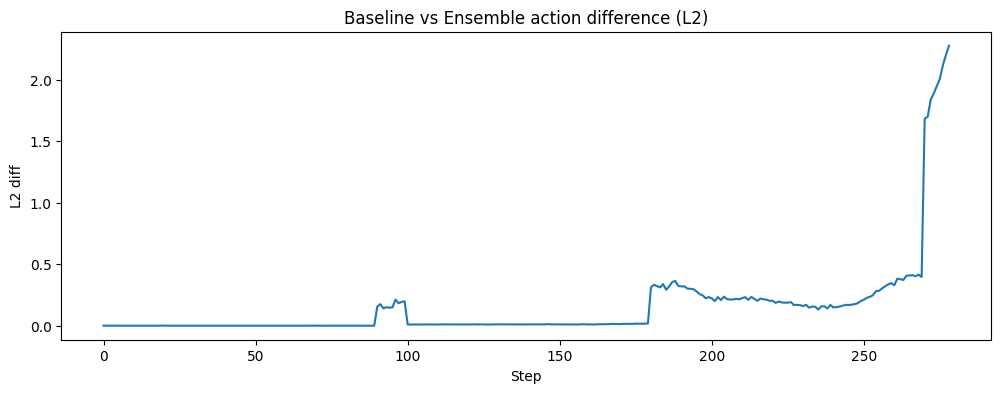

baseline mean jerk: 0.24277015030384064
ensemble mean jerk: 0.23310653865337372
baseline max jerk: 1.7951313257217407
ensemble max jerk: 0.5931246280670166


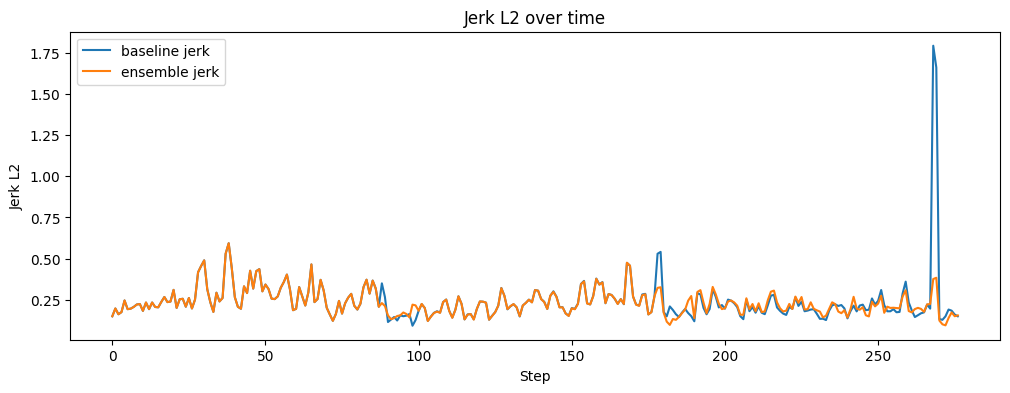

baseline boundary jump mean: 0.1733076125383377
ensemble boundary jump mean: 0.1677950620651245
baseline boundary jump max: 0.22712351381778717
ensemble boundary jump max: 0.22637151181697845
baseline boundary jerk mean: 0.2934454679489136
ensemble boundary jerk mean: 0.2763334810733795
baseline boundary jerk max: 0.377998411655426
ensemble boundary jerk max: 0.3765535056591034


In [15]:
import torch
import matplotlib.pyplot as plt

base = torch.load("outputs/debug_action_logs/100k_base/episode_0002.pt")
ens = torch.load("outputs/debug_action_logs/100k_01/episode_0002.pt")

base_actions = base["actions"]
ens_actions = ens["actions"]

if base_actions.ndim == 3:
    base_actions = base_actions.squeeze(1)
if ens_actions.ndim == 3:
    ens_actions = ens_actions.squeeze(1)

print("base shape:", base_actions.shape)
print("ens shape:", ens_actions.shape)

# 1) baseline vs ensemble 차이
T = min(base_actions.shape[0], ens_actions.shape[0])
base_actions = base_actions[:T]
ens_actions = ens_actions[:T]

diff = ens_actions - base_actions
diff_l2 = torch.norm(diff, dim=-1)

print("mean action diff L2:", diff_l2.mean().item())
print("max action diff L2:", diff_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(diff_l2.numpy())
plt.title("Baseline vs Ensemble action difference (L2)")
plt.xlabel("Step")
plt.ylabel("L2 diff")
plt.show()

# 2) jerk
base_jerk = base_actions[2:] - 2 * base_actions[1:-1] + base_actions[:-2]
ens_jerk = ens_actions[2:] - 2 * ens_actions[1:-1] + ens_actions[:-2]

base_jerk_l2 = torch.norm(base_jerk, dim=-1)
ens_jerk_l2 = torch.norm(ens_jerk, dim=-1)

print("baseline mean jerk:", base_jerk_l2.mean().item())
print("ensemble mean jerk:", ens_jerk_l2.mean().item())
print("baseline max jerk:", base_jerk_l2.max().item())
print("ensemble max jerk:", ens_jerk_l2.max().item())

plt.figure(figsize=(12, 4))
plt.plot(base_jerk_l2.numpy(), label="baseline jerk")
plt.plot(ens_jerk_l2.numpy(), label="ensemble jerk")
plt.legend()
plt.title("Jerk L2 over time")
plt.xlabel("Step")
plt.ylabel("Jerk L2")
plt.show()

# 3) boundary jump / boundary jerk
n_action_steps = 80

def boundary_jump(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        vals.append(torch.norm(actions[b] - actions[b - 1], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

def boundary_jerk(actions, n_action_steps):
    vals = []
    T = actions.shape[0]
    for b in range(n_action_steps, T, n_action_steps):
        if b >= 2:
            vals.append(torch.norm(actions[b] - 2 * actions[b - 1] + actions[b - 2], dim=-1))
    return torch.stack(vals) if len(vals) > 0 else None

base_jump = boundary_jump(base_actions, n_action_steps)
ens_jump = boundary_jump(ens_actions, n_action_steps)

base_bjerk = boundary_jerk(base_actions, n_action_steps)
ens_bjerk = boundary_jerk(ens_actions, n_action_steps)

if base_jump is not None and ens_jump is not None:
    print("baseline boundary jump mean:", base_jump.mean().item())
    print("ensemble boundary jump mean:", ens_jump.mean().item())
    print("baseline boundary jump max:", base_jump.max().item())
    print("ensemble boundary jump max:", ens_jump.max().item())

if base_bjerk is not None and ens_bjerk is not None:
    print("baseline boundary jerk mean:", base_bjerk.mean().item())
    print("ensemble boundary jerk mean:", ens_bjerk.mean().item())
    print("baseline boundary jerk max:", base_bjerk.max().item())
    print("ensemble boundary jerk max:", ens_bjerk.max().item())